## Productivity Analysis

In [1]:
import xarray as xr
import gsw
import PyCO2SYS as pyco2
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
from cmocean import cm
from salishsea_tools import visualisations as vis
import netCDF4 as nc
from matplotlib.colors import ListedColormap

In [2]:
meshxr = xr.open_dataset('/home/sallen/MEOPAR/grid/mesh_mask201702.nc')

def changemap(tracer,proj_data,base_data,ax, idx,*, colourbar=False):

    # tracer range lookup table
    levels_dict = {'no3': 1.5, 'biomass': 0.1, 'growth': 0.4}
    name_dict = {'no3': r'NO$_3$ ($\mu mol \, m^{-3}$)', 
                 'biomass': r'biomass', 'growth': r'growth'}
    
    # Ensure a symmetric range about zero
    limit = levels_dict[tracer]
    levels = np.linspace(-limit, limit, 50)

    # contour of change
    c = ax.contourf(
        base.gridX, base.gridY, proj_data[idx,...]-base_data[idx,...], 
        levels=levels,
        cmap=cm.balance, extend='both',antialiased=True,zorder=1,
    )
    # if colourbar==True:
    #     cax = fig.add_axes([1, 0.3, 0.01, 0.4])
    #     fig.colorbar(c, cax=cax, orientation='vertical',label=name_dict[tracer], ticks=[-limit,0,limit])
    cbar.ax.tick_params(labelsize=12) 
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.set_title(name_dict[tracer])
    ax.set_aspect(aspect=1)

    ax.set_xlabel("Model x")
    ax.set_ylabel("Model y")

    # Draw coastline
    ax.contourf(meshxr.tmask[0, 23, ...], levels=[-0.01, 0.01], colors='whitesmoke')
    ax.contour(meshxr.tmask[0, 0, ...], levels=[-0.01, 0.01], colors='lightgrey') # traditional coastline
    ax.contour(meshxr.tmask[0, 23, ...], levels=[-0.01, 0.01], colors='gray') # waterline at indice 23

In [3]:
# other grid files for thalweg plots
mesh = nc.Dataset('/home/sallen/MEOPAR/grid/mesh_mask201702.nc')
bathy = nc.Dataset("/home/sallen/MEOPAR/grid/bathymetry_202108.nc", mask_and_scale=False)
thalweg_in = '/home/sallen/MEOPAR/Tools/bathymetry/thalweg_working.txt'

## 5 year mean

In [ ]:
# load data
path='/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results'

base = xr.open_dataset(f"{path}/forthalweg_monthly_biology202111_20180101_20221231.nc").mean('time')

files = [f'{path}/All_{year}main_primarytracers_forthalweg_monthlybio_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
all = xr.open_mfdataset(files).mean('time')
files = [f'{path}/All_{year}main_primarytracers_forthalweg_monthly_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
allnit = xr.open_mfdataset(files).mean('time')


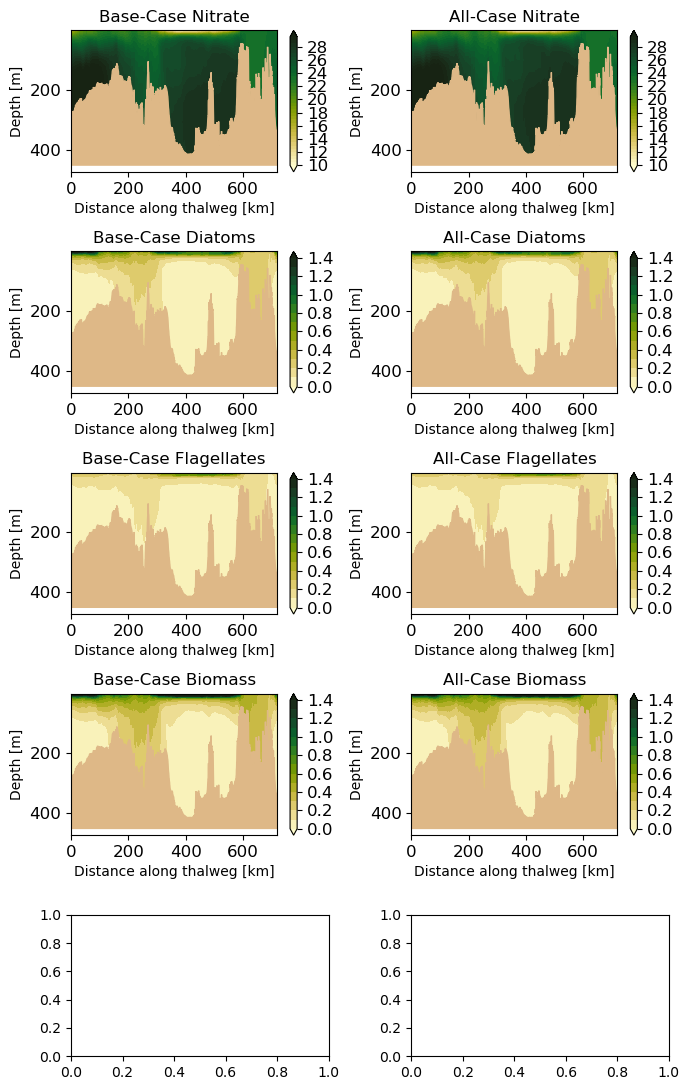

In [ ]:
mass_range = np.arange(0,1.5,0.1)
nit_range = np.arange(10,30,0.5)

fig, ax = plt.subplots(5,2,figsize=[7,11])

# column 1 is base-case
cbar = vis.contour_thalweg(ax[0,0], base.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0,0].tick_params(axis='both', which='major', labelsize=12)
ax[0,0].set_title('Base-Case Nitrate')

cbar = vis.contour_thalweg(ax[1,0], base.diatoms.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1,0].tick_params(axis='both', which='major', labelsize=12)
ax[1,0].set_title('Base-Case Diatoms')

cbar = vis.contour_thalweg(ax[2,0], base.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2,0].tick_params(axis='both', which='major', labelsize=12)
ax[2,0].set_title('Base-Case Flagellates')

cbar = vis.contour_thalweg(ax[3,0], base.diatoms.values + base.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3,0].tick_params(axis='both', which='major', labelsize=12)
ax[3,0].set_title('Base-Case Biomass')

# column 2 is all-case
cbar = vis.contour_thalweg(ax[0,1], allnit.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0,1].tick_params(axis='both', which='major', labelsize=12)
ax[0,1].set_title('All-Case Nitrate')

cbar = vis.contour_thalweg(ax[1,1], all.diatoms.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1,1].tick_params(axis='both', which='major', labelsize=12)
ax[1,1].set_title('All-Case Diatoms')

cbar = vis.contour_thalweg(ax[2,1], all.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2,1].tick_params(axis='both', which='major', labelsize=12)
ax[2,1].set_title('All-Case Flagellates')

cbar = vis.contour_thalweg(ax[3,1], all.diatoms.values + all.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3,1].tick_params(axis='both', which='major', labelsize=12)
ax[3,1].set_title('All-Case Biomass')

plt.tight_layout()

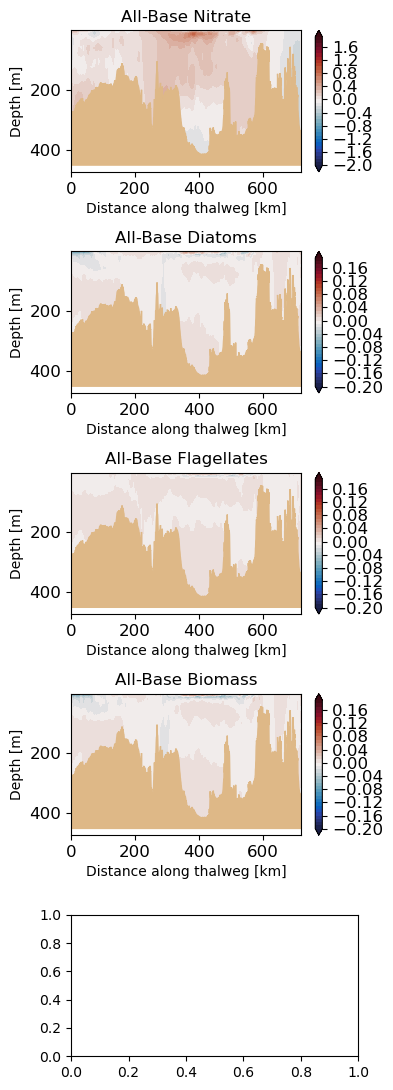

In [ ]:
mass_range = np.arange(-0.1,0.1,0.01)
nit_range = np.arange(-1.5,1.5,0.1)

fig, ax = plt.subplots(5,1,figsize=[4,11])

cbar = vis.contour_thalweg(ax[0], allnit.nitrate.values-base.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0].tick_params(axis='both', which='major', labelsize=12)
ax[0].set_title('All-Base Nitrate')

cbar = vis.contour_thalweg(ax[1], (all.diatoms.values)-(base.diatoms.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1].tick_params(axis='both', which='major', labelsize=12)
ax[1].set_title('All-Base Diatoms')

cbar = vis.contour_thalweg(ax[2], (all.flagellates.values)-(base.flagellates.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2].tick_params(axis='both', which='major', labelsize=12)
ax[2].set_title('All-Base Flagellates')

cbar = vis.contour_thalweg(ax[3], (all.diatoms.values + all.flagellates.values)-(base.diatoms.values + base.flagellates.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3].tick_params(axis='both', which='major', labelsize=12)
ax[3].set_title('All-Base Biomass')

plt.tight_layout()

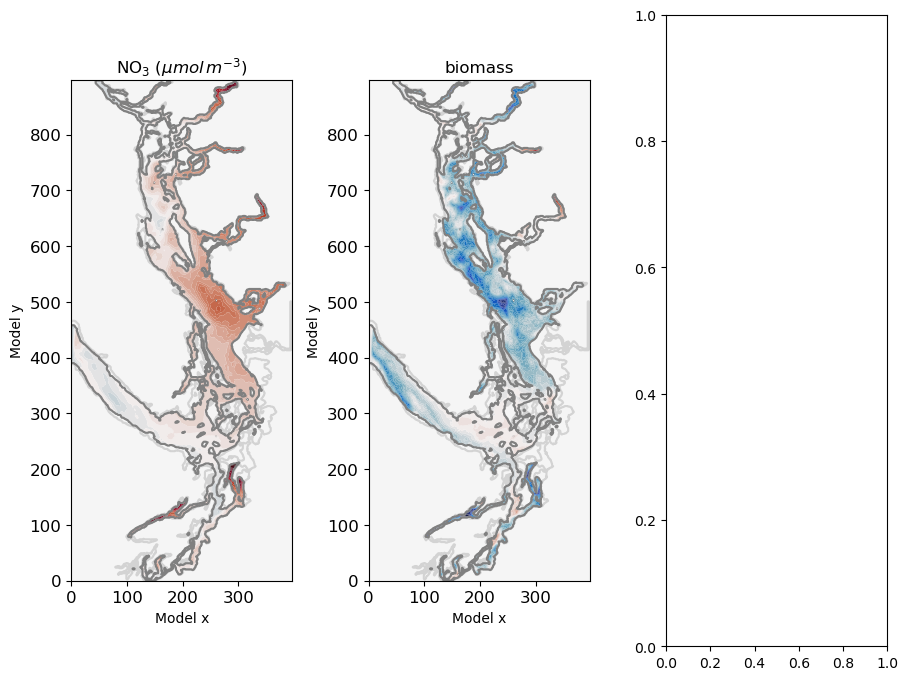

In [ ]:
# change at 10 m
fig, ax= plt.subplots(1,3,figsize=[398/130*3,898/130])

changemap('no3',allnit.nitrate.values,base.nitrate.values,ax[0],idx=10)
changemap('biomass',all.diatoms.values+all.flagellates.values,base.diatoms.values+base.flagellates.values,ax[1],idx=10)

plt.tight_layout()

## seasonal

In [5]:
# load data
path='/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results'

base = xr.open_dataset("/ocean/rbeutel/MOAD/analysis-becca/projections/summary_results/forthalweg_monthly_biology202111_20180101_20221231.nc")

files = [f'{path}/All_{year}main_primarytracers_forthalweg_monthlybio_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
all = xr.open_mfdataset(files)
files = [f'{path}/All_{year}main_primarytracers_forthalweg_monthly_{year}0101_{year}1231.nc' for year in range(2018,2022+1)]
allnit = xr.open_mfdataset(files)

In [8]:
winterbool= (pd.to_datetime(all.time.values).month <=2) | (pd.to_datetime(all.time.values).month ==12)
_,winterbool,_,_ = np.meshgrid(all.depth.values,winterbool,all.gridY.values,all.gridX.values)
allwinter = all.where(winterbool).mean('time')

allwinter['nitrate'] = allnit.where(winterbool).mean('time').nitrate

In [9]:
summerbool= (pd.to_datetime(all.time.values).month >=6) & (pd.to_datetime(all.time.values).month <=8)
_,summerbool,_,_ = np.meshgrid(all.depth.values,summerbool,all.gridY.values,all.gridX.values)
allsummer = all.where(summerbool).mean('time')

allsummer['nitrate'] = allnit.where(summerbool).mean('time').nitrate

In [10]:
winterbool= (pd.to_datetime(base.time.values).month <=2) | (pd.to_datetime(base.time.values).month ==12)
_,winterbool,_,_ = np.meshgrid(base.depth.values,winterbool,base.gridY.values,base.gridX.values)
basewinter = base.where(winterbool).mean('time')

In [11]:
summerbool= (pd.to_datetime(base.time.values).month >=6) & (pd.to_datetime(base.time.values).month <=8)
_,summerbool,_,_ = np.meshgrid(base.depth.values,summerbool,base.gridY.values,base.gridX.values)
basesummer = base.where(summerbool).mean('time')

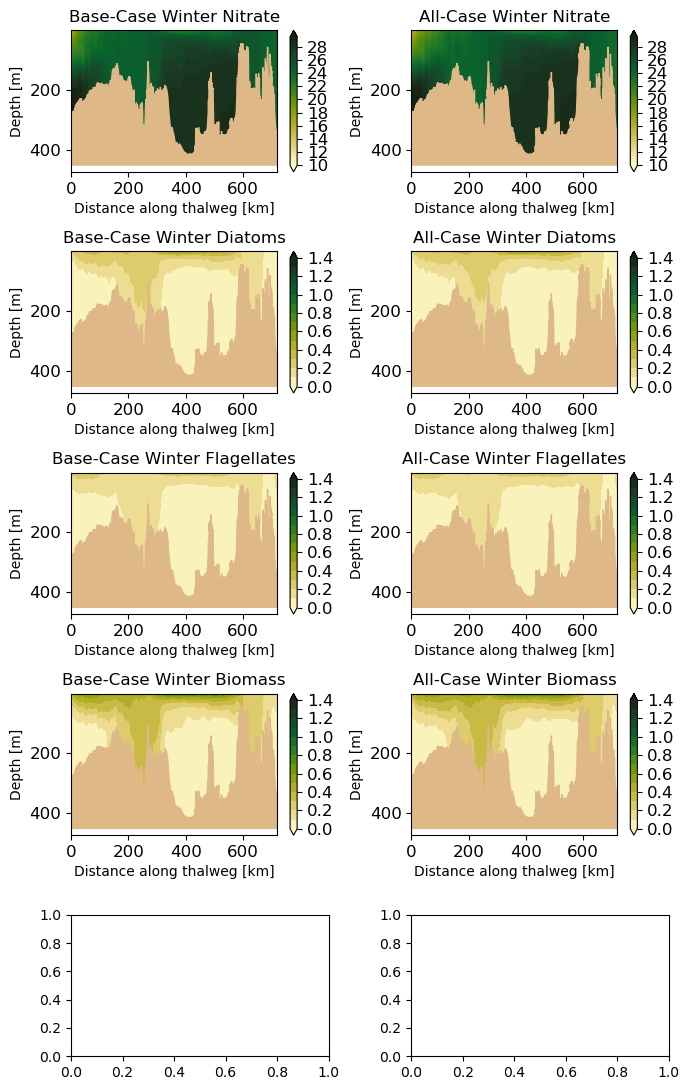

In [12]:
mass_range = np.arange(0,1.5,0.1)
nit_range = np.arange(10,30,0.5)

fig, ax = plt.subplots(5,2,figsize=[7,11])

# column 1 is base-case
cbar = vis.contour_thalweg(ax[0,0], basewinter.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0,0].tick_params(axis='both', which='major', labelsize=12)
ax[0,0].set_title('Base-Case Winter Nitrate')

cbar = vis.contour_thalweg(ax[1,0], basewinter.diatoms.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1,0].tick_params(axis='both', which='major', labelsize=12)
ax[1,0].set_title('Base-Case Winter Diatoms')

cbar = vis.contour_thalweg(ax[2,0], basewinter.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2,0].tick_params(axis='both', which='major', labelsize=12)
ax[2,0].set_title('Base-Case Winter Flagellates')

cbar = vis.contour_thalweg(ax[3,0], basewinter.diatoms.values + basewinter.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3,0].tick_params(axis='both', which='major', labelsize=12)
ax[3,0].set_title('Base-Case Winter Biomass')

# column 2 is all-case
cbar = vis.contour_thalweg(ax[0,1], allwinter.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0,1].tick_params(axis='both', which='major', labelsize=12)
ax[0,1].set_title('All-Case Winter Nitrate')

cbar = vis.contour_thalweg(ax[1,1], allwinter.diatoms.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1,1].tick_params(axis='both', which='major', labelsize=12)
ax[1,1].set_title('All-Case Winter Diatoms')

cbar = vis.contour_thalweg(ax[2,1], allwinter.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2,1].tick_params(axis='both', which='major', labelsize=12)
ax[2,1].set_title('All-Case Winter Flagellates')

cbar = vis.contour_thalweg(ax[3,1], allwinter.diatoms.values + allwinter.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3,1].tick_params(axis='both', which='major', labelsize=12)
ax[3,1].set_title('All-Case Winter Biomass')

plt.tight_layout()

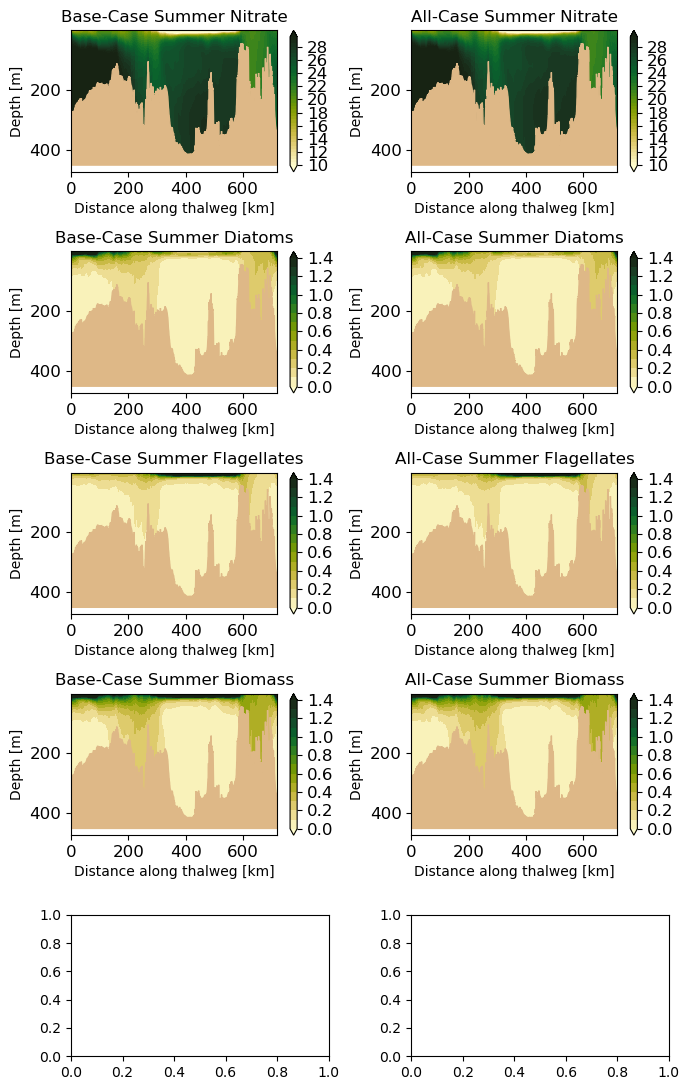

In [13]:
mass_range = np.arange(0,1.5,0.1)
nit_range = np.arange(10,30,0.5)

fig, ax = plt.subplots(5,2,figsize=[7,11])

# column 1 is base-case
cbar = vis.contour_thalweg(ax[0,0], basesummer.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0,0].tick_params(axis='both', which='major', labelsize=12)
ax[0,0].set_title('Base-Case Summer Nitrate')

cbar = vis.contour_thalweg(ax[1,0], basesummer.diatoms.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1,0].tick_params(axis='both', which='major', labelsize=12)
ax[1,0].set_title('Base-Case Summer Diatoms')

cbar = vis.contour_thalweg(ax[2,0], basesummer.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2,0].tick_params(axis='both', which='major', labelsize=12)
ax[2,0].set_title('Base-Case Summer Flagellates')

cbar = vis.contour_thalweg(ax[3,0], basesummer.diatoms.values + basesummer.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3,0].tick_params(axis='both', which='major', labelsize=12)
ax[3,0].set_title('Base-Case Summer Biomass')

# column 2 is all-case
cbar = vis.contour_thalweg(ax[0,1], allsummer.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0,1].tick_params(axis='both', which='major', labelsize=12)
ax[0,1].set_title('All-Case Summer Nitrate')

cbar = vis.contour_thalweg(ax[1,1], allsummer.diatoms.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1,1].tick_params(axis='both', which='major', labelsize=12)
ax[1,1].set_title('All-Case Summer Diatoms')

cbar = vis.contour_thalweg(ax[2,1], allsummer.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2,1].tick_params(axis='both', which='major', labelsize=12)
ax[2,1].set_title('All-Case Summer Flagellates')

cbar = vis.contour_thalweg(ax[3,1], allsummer.diatoms.values + allsummer.flagellates.values, bathy, mesh, clevels=mass_range, cmap = cm.speed, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3,1].tick_params(axis='both', which='major', labelsize=12)
ax[3,1].set_title('All-Case Summer Biomass')

plt.tight_layout()

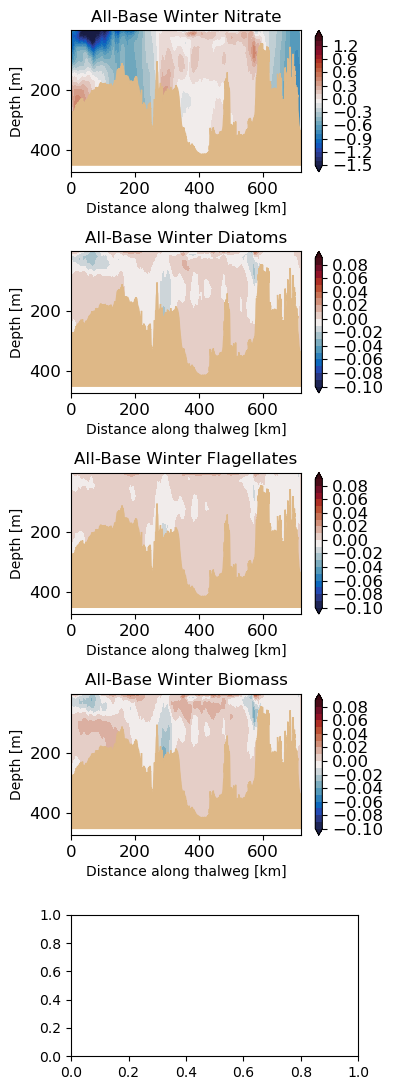

In [14]:
mass_range = np.arange(-0.1,0.1,0.01)
nit_range = np.arange(-1.5,1.5,0.1)

fig, ax = plt.subplots(5,1,figsize=[4,11])

cbar = vis.contour_thalweg(ax[0], allwinter.nitrate.values-basewinter.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0].tick_params(axis='both', which='major', labelsize=12)
ax[0].set_title('All-Base Winter Nitrate')

cbar = vis.contour_thalweg(ax[1], (allwinter.diatoms.values)-(basewinter.diatoms.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1].tick_params(axis='both', which='major', labelsize=12)
ax[1].set_title('All-Base Winter Diatoms')

cbar = vis.contour_thalweg(ax[2], (allwinter.flagellates.values)-(basewinter.flagellates.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2].tick_params(axis='both', which='major', labelsize=12)
ax[2].set_title('All-Base Winter Flagellates')

cbar = vis.contour_thalweg(ax[3], (allwinter.diatoms.values + allwinter.flagellates.values)-(basewinter.diatoms.values + basewinter.flagellates.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3].tick_params(axis='both', which='major', labelsize=12)
ax[3].set_title('All-Base Winter Biomass')

plt.tight_layout()

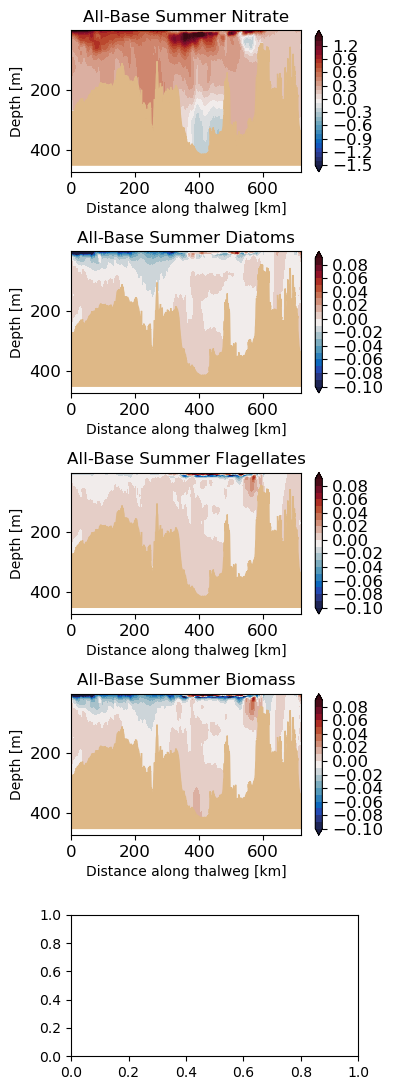

In [18]:
mass_range = np.arange(-0.1,0.1,0.01)
nit_range = np.arange(-1.5,1.5,0.1)

fig, ax = plt.subplots(5,1,figsize=[4,11])

cbar = vis.contour_thalweg(ax[0], allsummer.nitrate.values-basesummer.nitrate.values, bathy, mesh, clevels=nit_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[0].tick_params(axis='both', which='major', labelsize=12)
ax[0].set_title('All-Base Summer Nitrate')

cbar = vis.contour_thalweg(ax[1], (allsummer.diatoms.values)-(basesummer.diatoms.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[1].tick_params(axis='both', which='major', labelsize=12)
ax[1].set_title('All-Base Summer Diatoms')

cbar = vis.contour_thalweg(ax[2], (allsummer.flagellates.values)-(basesummer.flagellates.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[2].tick_params(axis='both', which='major', labelsize=12)
ax[2].set_title('All-Base Summer Flagellates')

cbar = vis.contour_thalweg(ax[3], (allsummer.diatoms.values + allsummer.flagellates.values)-(basesummer.diatoms.values + basesummer.flagellates.values), bathy, mesh, clevels=mass_range, cmap = cm.balance, thalweg_file=thalweg_in)
# cbar.set_label('Salinity [g/kg]', fontsize = 12)
cbar.ax.tick_params(labelsize=12) 
ax[3].tick_params(axis='both', which='major', labelsize=12)
ax[3].set_title('All-Base Summer Biomass')

plt.tight_layout()

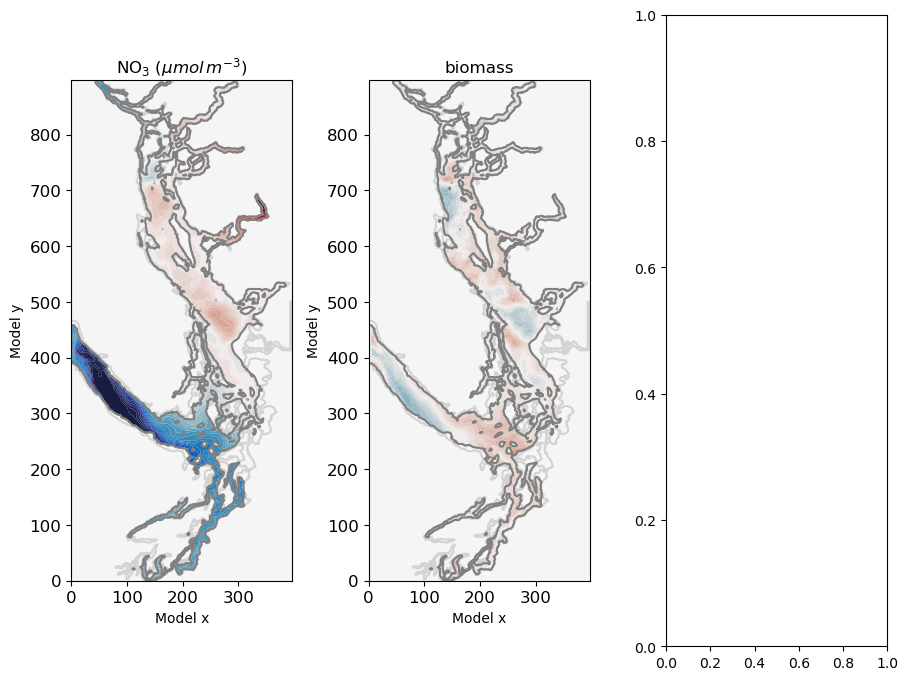

In [16]:
# change at 10 m
fig, ax= plt.subplots(1,3,figsize=[398/130*3,898/130])

changemap('no3',allwinter.nitrate.values,basewinter.nitrate.values,ax[0],idx=10)
changemap('biomass',allwinter.diatoms.values+allwinter.flagellates.values,basewinter.diatoms.values+basewinter.flagellates.values,ax[1],idx=10)

plt.tight_layout()

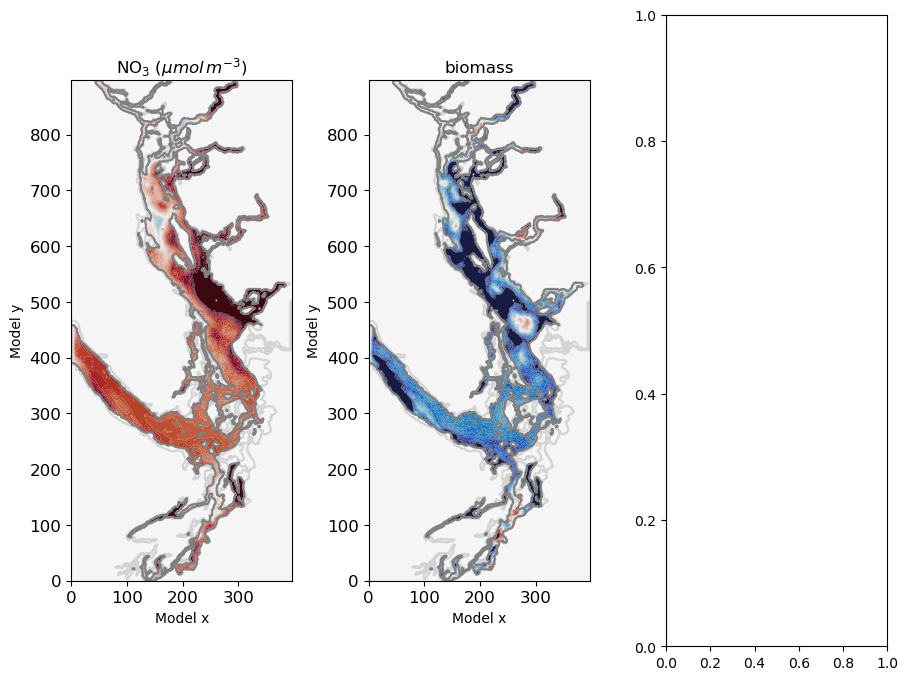

In [17]:
# change at 10 m
fig, ax= plt.subplots(1,3,figsize=[398/130*3,898/130])

changemap('no3',allsummer.nitrate.values,basesummer.nitrate.values,ax[0],idx=10)
changemap('biomass',allsummer.diatoms.values+allsummer.flagellates.values,basesummer.diatoms.values+basesummer.flagellates.values,ax[1],idx=10)

plt.tight_layout()